In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

In [110]:
df = pd.read_csv('sleep.csv')
df

,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,USR-08496,61,Female,Remote Tech,Night Owl,18,Streaming (Netflix/Hulu),61,1,60,74,21.0,5.57,26.5,18.1,3,3.2,Moderate Debt
8496,USR-08497,64,Male,Student,Night Owl,138,TikTok / Reels,58,1,0,58,84.3,3.99,20.4,19.4,7,10.0,Severe Sleep Debt
8497,USR-08498,34,Male,Corporate 9-to-5,Intermediate,56,Streaming (Netflix/Hulu),56,0,94,33,40.6,7.58,17.4,20.7,2,3.7,Mild Deficit
8498,USR-08499,23,Male,Healthcare / Shift Worker,Night Owl,165,TikTok / Reels,72,0,0,52,123.3,3.20,14.2,15.8,7,10.0,Severe Sleep Debt


## Part I

## Question 1

In [111]:
df = df.drop(columns=['user_id','next_day_fatigue_score']) 

I dropped the used_id and next_day_fatigue_score columns because they are not necessay in this part.

In [112]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
target_col = 'sleep_debt_category'

if target_col in numerical_cols:
    numerical_cols.remove(target_col)

if target_col in categorical_cols:
    categorical_cols.remove(target_col)

print(str(len(numerical_cols)) + " Numerical columns")
print(str(len(categorical_cols)) + " Categorical columns")

print("Numerical columns: " + str(numerical_cols))
print("Categorical columns: " + str(categorical_cols))

df[numerical_cols].describe().T

11 Numerical columns
4 Categorical columns
Numerical columns: ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes']
Categorical columns: ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app']


,count,mean,std,min,25%,50%,75%,max
age,8500.0,34.355647,11.584259,18.0,25.00,32.00,42.00,65.0
bedtime_phone_minutes,8500.0,59.250000,36.931991,1.0,31.00,51.00,79.00,180.0
screen_brightness_pct,8500.0,55.153882,19.850550,10.0,42.00,55.00,69.00,100.0
blue_light_filter_active,8500.0,0.467765,0.498989,0.0,0.00,0.00,1.00,1.0
caffeine_post_5pm_mg,8500.0,33.222471,51.935645,0.0,0.00,0.00,55.00,250.0
physical_activity_min,8500.0,35.701412,20.819390,0.0,21.00,35.00,50.00,112.0
sleep_latency_min,8500.0,40.671471,17.444914,6.0,28.20,37.60,49.70,123.3
total_sleep_hours,8500.0,6.266209,1.446258,3.2,5.24,6.33,7.35,9.8
deep_sleep_pct,8500.0,21.735741,3.069377,8.1,19.70,21.90,23.90,28.0
rem_sleep_pct,8500.0,19.105859,2.546459,9.6,17.40,19.10,20.80,27.0


In [113]:
df.isna().sum()

age                         0
gender                      0
occupation_type             0
chronotype                  0
bedtime_phone_minutes       0
primary_bedtime_app         0
screen_brightness_pct       0
blue_light_filter_active    0
caffeine_post_5pm_mg        0
physical_activity_min       0
sleep_latency_min           0
total_sleep_hours           0
deep_sleep_pct              0
rem_sleep_pct               0
morning_alarm_snoozes       0
sleep_debt_category         0
dtype: int64

I verify that there are no missing values, because they would give wrong results.

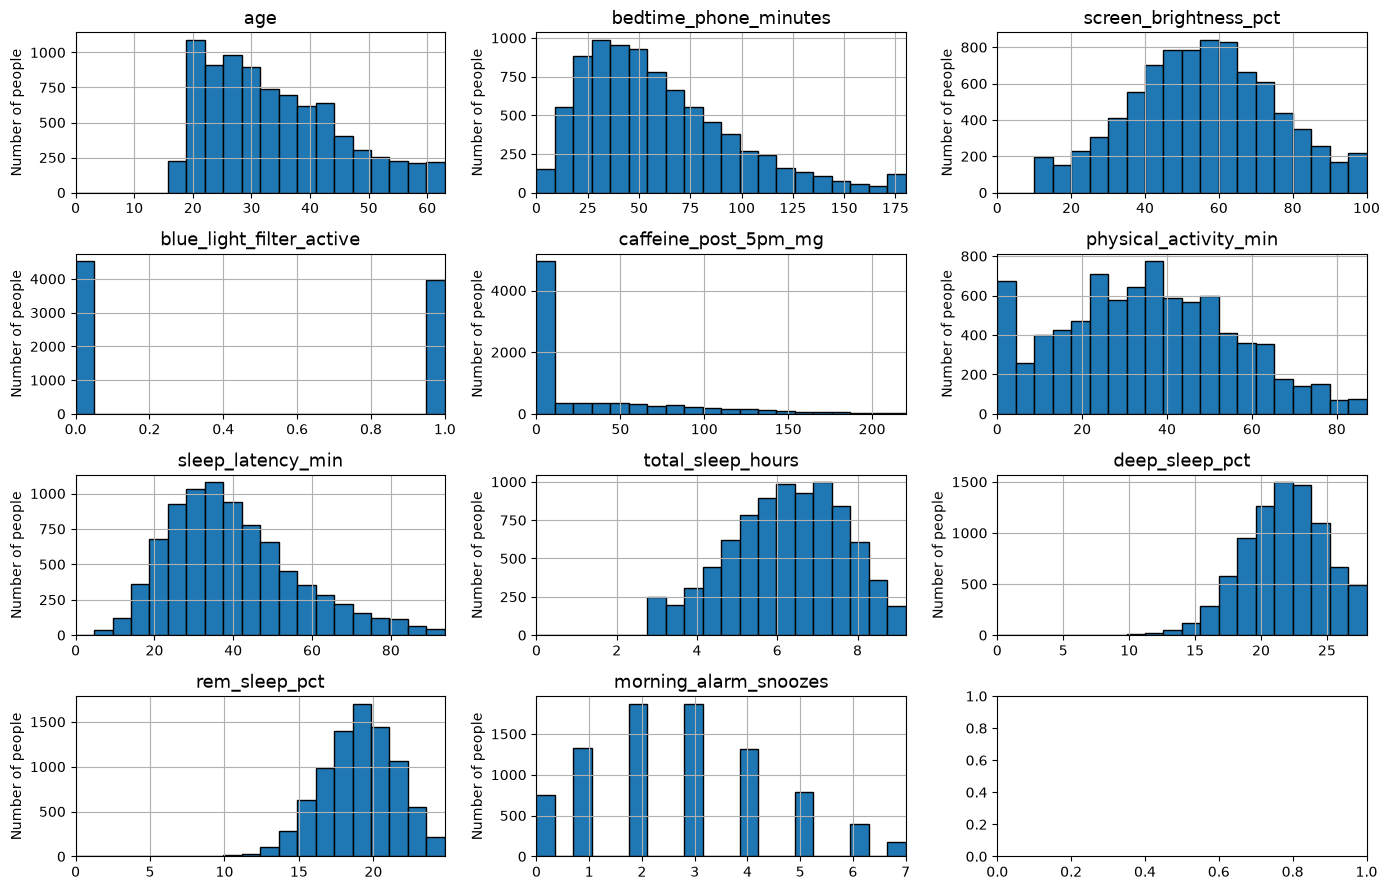

In [114]:
fig, axes = plt.subplots(4, 3, figsize=(14, 9))
axes = axes.flatten()

for i in range(len(numerical_cols)):
    col = numerical_cols[i]
    ax = axes[i]
    limite = df[col].quantile(0.99) # We set the limit to the 99th percentile
    df[col].hist(bins=20, edgecolor='black', ax=ax, range=(0, limite))
    ax.set_xlim(0, limite)
    ax.set_title(col, fontsize=13)
    ax.set_ylabel('Number of people')

plt.tight_layout()
plt.show()

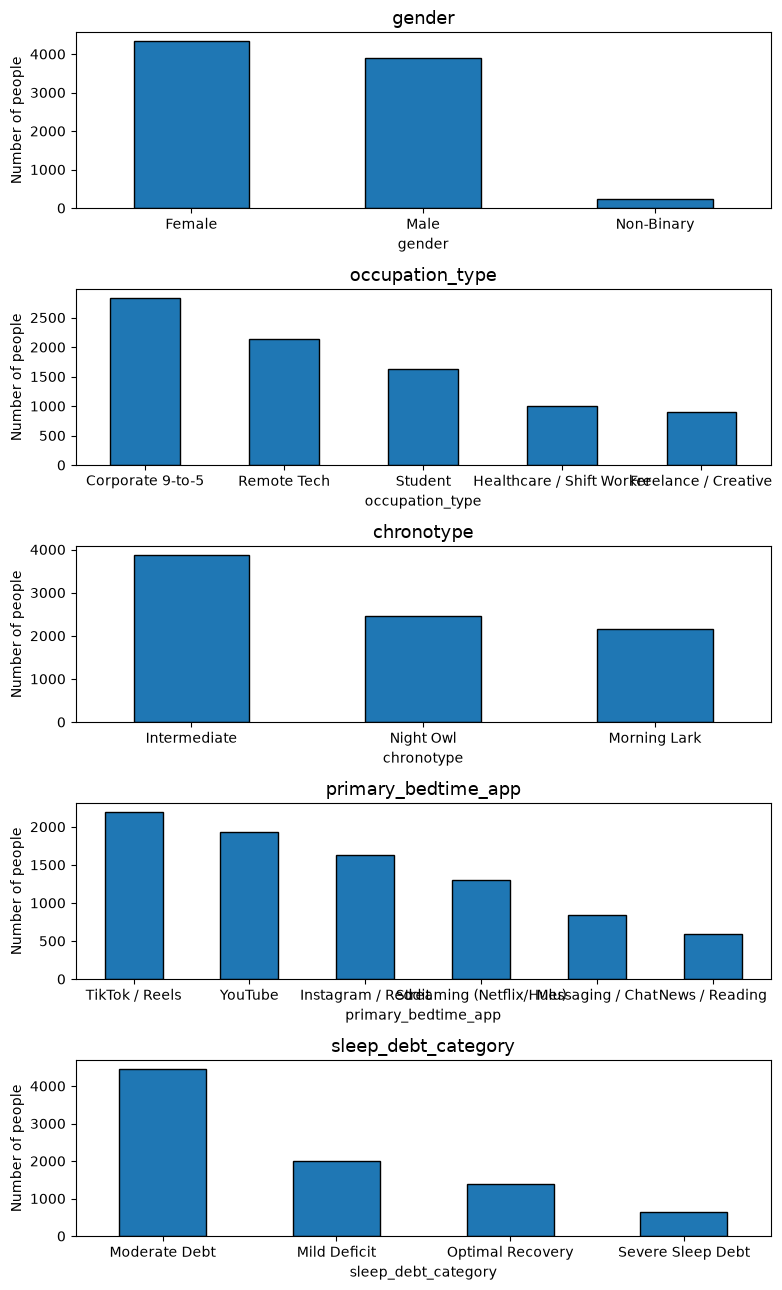

In [115]:
cols_to_plot = categorical_cols + [target_col]

fig, axes = plt.subplots(5, 1, figsize=(8, 13))
axes = axes.flatten()

for i in range(len(cols_to_plot)):
    col = cols_to_plot[i]
    ax = axes[i]
    df[col].value_counts().plot(kind='bar', edgecolor='black', ax=ax)
    ax.set_title(col, fontsize=13)
    ax.set_ylabel('Number of people')
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [116]:
class_balance = pd.DataFrame({'Count': df[target_col].value_counts(),'Percentage (%)': (df[target_col].value_counts(normalize=True) * 100).round(2)})
class_balance

,Count,Percentage (%)
sleep_debt_category,,
Moderate Debt,4462,52.49
Mild Deficit,2004,23.58
Optimal Recovery,1387,16.32
Severe Sleep Debt,647,7.61


The classes are imbalanced (52% moderate debt for only 7% severe sleep debt). I will need to stratify and to balance the accuracy.

## Question 3

In [117]:
df = pd.get_dummies(df, columns=categorical_cols, dtype=int)
df

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Student,chronotype_Intermediate,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,0,1,0,0,1,0,0,0,0,0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,1,1,0,0,0,0,0,0,0,1
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,0,0,0,1,0,0,0,0,1,0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,0,1,0,0,0,0,0,0,0,1
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,0,1,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,61,18,61,1,60,74,21.0,5.57,26.5,18.1,...,0,0,0,1,0,0,0,1,0,0
8496,64,138,58,1,0,58,84.3,3.99,20.4,19.4,...,1,0,0,1,0,0,0,0,1,0
8497,34,56,56,0,94,33,40.6,7.58,17.4,20.7,...,0,1,0,0,0,0,0,1,0,0
8498,23,165,72,0,0,52,123.3,3.20,14.2,15.8,...,0,0,0,1,0,0,0,0,1,0


## Question 4

In [118]:
X = df.drop(columns=[target_col])
y = df[target_col]

# I separate the dataset into three parts: training, validation, and test.
# First I separate the test set (10%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.1, stratify=y, random_state=0)

# Then I separate the training from the validation (20/80) in the rest.
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2/0.9, stratify=y_temp, random_state=0)

print(len(X_train), len(X_val), len(X_test))


5949 1701 850


## Question 5

In [119]:
# StandardScaler has to only learn from the training data.
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

n = len(X_train)
k_values = [3, 5, 15, 50, int(round(np.sqrt(n)))] 

results = []
for k in k_values:
    for w in ['uniform', 'distance']:
        knn = KNeighborsClassifier(n_neighbors=k, weights=w).fit(X_train_s, y_train)
        row = {'k': k, 'weights': w}
        for name, Xs, ys in [('train', X_train_s, y_train), ('val', X_val_s, y_val)]:
            p = knn.predict(Xs)
            row[f'Accuracy {name}'] = accuracy_score(ys, p)
            row[f'Precision {name}'] = precision_score(ys, p, average='macro', zero_division=0)
            row[f'Recall {name}'] = recall_score(ys, p, average='macro')
            row[f'F1 {name}'] = f1_score(ys, p, average='macro')
            row[f'Balanced Acc {name}'] = balanced_accuracy_score(ys, p)
        results.append(row)

df_results = pd.DataFrame(results).round(3)
df_results


,k,weights,Accuracy train,Precision train,Recall train,F1 train,Balanced Acc train,Accuracy val,Precision val,Recall val,F1 val,Balanced Acc val
0,3,uniform,0.842,0.847,0.791,0.814,0.791,0.704,0.679,0.623,0.646,0.623
1,3,distance,1.000,1.000,1.000,1.000,1.000,0.700,0.667,0.621,0.640,0.621
2,5,uniform,0.810,0.827,0.737,0.770,0.737,0.715,0.721,0.619,0.653,0.619
3,5,distance,1.000,1.000,1.000,1.000,1.000,0.709,0.700,0.615,0.644,0.615
4,15,uniform,0.764,0.795,0.646,0.685,0.646,0.727,0.752,0.606,0.647,0.606
5,15,distance,1.000,1.000,1.000,1.000,1.000,0.724,0.744,0.608,0.646,0.608
6,50,uniform,0.748,0.792,0.588,0.623,0.588,0.748,0.783,0.602,0.644,0.602
7,50,distance,1.000,1.000,1.000,1.000,1.000,0.745,0.779,0.601,0.643,0.601
8,77,uniform,0.736,0.783,0.567,0.601,0.567,0.743,0.780,0.581,0.620,0.581
9,77,distance,1.000,1.000,1.000,1.000,1.000,0.741,0.773,0.586,0.625,0.586


I obtained the best resulats for k=5 and for uniform weights. I keep these values in the next question

## Question 6

In [120]:
best_k= 5
best_w ='uniform'

# Best model trained on train only
knn = KNeighborsClassifier(n_neighbors=best_k, weights=best_w).fit(X_train_s, y_train)
y_train_pred = knn.predict(X_train_s)
y_val_pred = knn.predict(X_val_s)

#  I merge train and validation
X_full = pd.concat([X_train, X_val])
y_full = pd.concat([y_train, y_val])

# New scaler is fitted on train and validation
scaler_full = StandardScaler()
X_full_s = scaler_full.fit_transform(X_full)
X_test_s = scaler_full.transform(X_test)

# Final model and evaluation on test
knn_full = KNeighborsClassifier(n_neighbors=best_k, weights=best_w).fit(X_full_s, y_full)
y_test_pred = knn_full.predict(X_test_s)

# Comparaison of results on train, validation and test sets.
comparison = pd.DataFrame({'Results on train (fitted on train)': {'Accuracy': accuracy_score(y_train, y_train_pred),
        'Precision': precision_score(y_train, y_train_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_train, y_train_pred, average='macro'),
        'F1': f1_score(y_train, y_train_pred, average='macro'),
        'Balanced Acc': balanced_accuracy_score(y_train, y_train_pred)},

    'Results on validation (fitted on train)': {'Accuracy': accuracy_score(y_val, y_val_pred),
        'Precision': precision_score(y_val, y_val_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_val, y_val_pred, average='macro'),
        'F1': f1_score(y_val, y_val_pred, average='macro'),
        'Balanced Acc': balanced_accuracy_score(y_val, y_val_pred)},

    'Results on test (fitted on train + validation)': {'Accuracy': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_test_pred, average='macro'),
        'F1': f1_score(y_test, y_test_pred, average='macro'),
        'Balanced Acc': balanced_accuracy_score(y_test, y_test_pred)}
}).T.round(3)

comparison


,Accuracy,Precision,Recall,F1,Balanced Acc
Results on train (fitted on train),0.810,0.827,0.737,0.770,0.737
Results on validation (fitted on train),0.715,0.721,0.619,0.653,0.619
Results on test (fitted on train + validation),0.718,0.769,0.618,0.663,0.618


## Question 7

In [121]:
X_train_cv, X_test_cv, y_train_cv, y_test_cv = train_test_split(X, y, test_size=0.1, stratify=y, random_state=0)

# 5-Fold stratified CV on the train set
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

n = len(X_train_cv) * 4 // 5 
k_values = [3, 5, 15, 50, int(round(np.sqrt(n)))]  

rows = []
for k in k_values:
    for w in ['uniform', 'distance']:
        # Scaler inside the Pipeline, so it is refitted on each fold
        pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=k, weights=w))])
        cv = cross_validate(pipe, X_train_cv, y_train_cv, cv=skf, scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'balanced_accuracy'])
        rows.append({'k': k,
            'weights': w,
            'Accuracy': cv['test_accuracy'].mean(),
            'Precision': cv['test_precision_macro'].mean(),
            'Recall': cv['test_recall_macro'].mean(),
            'F1': cv['test_f1_macro'].mean(),
            'Balanced Acc': cv['test_balanced_accuracy'].mean()})

cv_results = pd.DataFrame(rows).round(3)
cv_results


,k,weights,Accuracy,Precision,Recall,F1,Balanced Acc
0,3,uniform,0.704,0.695,0.616,0.643,0.616
1,3,distance,0.702,0.684,0.614,0.639,0.614
2,5,uniform,0.708,0.716,0.611,0.643,0.611
3,5,distance,0.706,0.700,0.609,0.638,0.609
4,15,uniform,0.714,0.746,0.590,0.627,0.590
5,15,distance,0.719,0.746,0.596,0.633,0.596
6,50,uniform,0.731,0.774,0.575,0.611,0.575
7,50,distance,0.731,0.771,0.579,0.616,0.579
8,78,uniform,0.729,0.775,0.558,0.590,0.558
9,78,distance,0.730,0.774,0.565,0.597,0.565


I have the best results of F1 and Balanced Acc for k=3, weights=uniform

In [122]:
best_k = 3
best_w = 'uniform'

pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=best_k, weights=best_w))])
cv = cross_validate(pipe, X_train_cv, y_train_cv, cv=skf,
                    scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'balanced_accuracy'])

# 95 % CI: mean ± t * s / √5
t = 2.776
acc = cv['test_accuracy']
prec = cv['test_precision_macro']
rec = cv['test_recall_macro']
f1 = cv['test_f1_macro']
bal = cv['test_balanced_accuracy']

ci_table = pd.DataFrame({'Mean': [acc.mean(), prec.mean(), rec.mean(), f1.mean(), bal.mean()],
    'CI low': [acc.mean() - t * acc.std(ddof=1) / np.sqrt(5),
               prec.mean() - t * prec.std(ddof=1) / np.sqrt(5),
               rec.mean() - t * rec.std(ddof=1) / np.sqrt(5),
               f1.mean() - t * f1.std(ddof=1) / np.sqrt(5),
               bal.mean() - t * bal.std(ddof=1) / np.sqrt(5)],
    'CI high': [acc.mean() + t * acc.std(ddof=1) / np.sqrt(5),
                prec.mean() + t * prec.std(ddof=1) / np.sqrt(5),
                rec.mean() + t * rec.std(ddof=1) / np.sqrt(5),
                f1.mean() + t * f1.std(ddof=1) / np.sqrt(5),
                bal.mean() + t * bal.std(ddof=1) / np.sqrt(5)]}, index=['Accuracy', 'Precision', 'Recall', 'F1', 'Balanced Acc']).round(3)

ci_table

,Mean,CI low,CI high
Accuracy,0.704,0.691,0.717
Precision,0.695,0.684,0.707
Recall,0.616,0.590,0.643
F1,0.643,0.622,0.664
Balanced Acc,0.616,0.590,0.643


## Question 8

In [123]:
pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])

param_grid = {'knn__n_neighbors': k_values,'knn__weights': ['uniform', 'distance']}

# In the Inner loop: GridSearch with 5-fold CV, best model chosen odepending on F1
grid = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0), scoring='f1_macro')

# In the Outer loop: 3-fold CV
nested = cross_validate(grid, X_train_cv, y_train_cv, cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=0),
                        scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'balanced_accuracy'],
                        return_estimator=True)

nested_results = pd.DataFrame({
    'Best k': [est.best_params_['knn__n_neighbors'] for est in nested['estimator']],
    'Best weights': [est.best_params_['knn__weights'] for est in nested['estimator']],
    'Accuracy': nested['test_accuracy'],
    'Precision': nested['test_precision_macro'],
    'Recall': nested['test_recall_macro'],
    'F1': nested['test_f1_macro'],
    'Balanced Acc': nested['test_balanced_accuracy']}, index=['Fold 1', 'Fold 2', 'Fold 3']).round(3)

nested_results

,Best k,Best weights,Accuracy,Precision,Recall,F1,Balanced Acc
Fold 1,5,uniform,0.697,0.711,0.594,0.627,0.594
Fold 2,3,uniform,0.695,0.705,0.602,0.636,0.602
Fold 3,5,uniform,0.712,0.722,0.609,0.645,0.609


In the end, the best hyper parameters are k=5 and weignts=uniform

## Part II

## Question 1

In [124]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold

df = pd.read_csv('sleep.csv')
df = df.drop(columns=['user_id','sleep_debt_category'])

In [125]:
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
target_col = 'next_day_fatigue_score'

if target_col in numerical_cols:
    numerical_cols.remove(target_col)

if target_col in categorical_cols:
    categorical_cols.remove(target_col)

print(str(len(numerical_cols)) + " Numerical columns")
print(str(len(categorical_cols)) + " Categorical columns")

print("Numerical columns: " + str(numerical_cols))
print("Categorical columns: " + str(categorical_cols))

df[numerical_cols].describe().T

11 Numerical columns
4 Categorical columns
Numerical columns: ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes']
Categorical columns: ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app']


,count,mean,std,min,25%,50%,75%,max
age,8500.0,34.355647,11.584259,18.0,25.00,32.00,42.00,65.0
bedtime_phone_minutes,8500.0,59.250000,36.931991,1.0,31.00,51.00,79.00,180.0
screen_brightness_pct,8500.0,55.153882,19.850550,10.0,42.00,55.00,69.00,100.0
blue_light_filter_active,8500.0,0.467765,0.498989,0.0,0.00,0.00,1.00,1.0
caffeine_post_5pm_mg,8500.0,33.222471,51.935645,0.0,0.00,0.00,55.00,250.0
physical_activity_min,8500.0,35.701412,20.819390,0.0,21.00,35.00,50.00,112.0
sleep_latency_min,8500.0,40.671471,17.444914,6.0,28.20,37.60,49.70,123.3
total_sleep_hours,8500.0,6.266209,1.446258,3.2,5.24,6.33,7.35,9.8
deep_sleep_pct,8500.0,21.735741,3.069377,8.1,19.70,21.90,23.90,28.0
rem_sleep_pct,8500.0,19.105859,2.546459,9.6,17.40,19.10,20.80,27.0


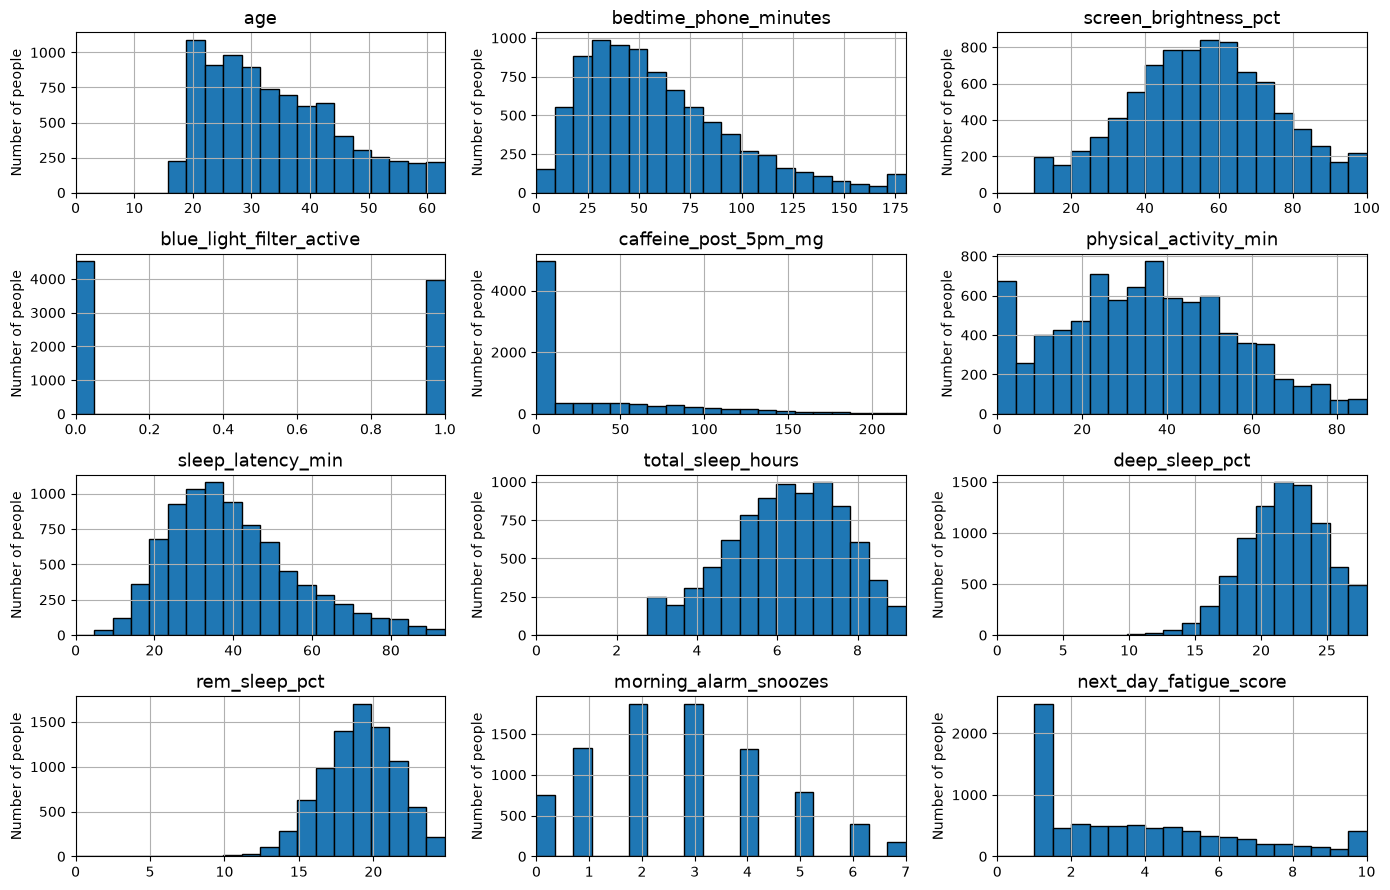

In [126]:
cols_to_plot = numerical_cols + [target_col]

fig, axes = plt.subplots(4, 3, figsize=(14, 9))
axes = axes.flatten()

for i in range(len(cols_to_plot)):
    col = cols_to_plot[i]
    ax = axes[i]
    limite = df[col].quantile(0.99) # We set the limit to the 99th percentile
    df[col].hist(bins=20, edgecolor='black', ax=ax, range=(0, limite))
    ax.set_xlim(0, limite)
    ax.set_title(col, fontsize=13)
    ax.set_ylabel('Number of people')

plt.tight_layout()
plt.show()

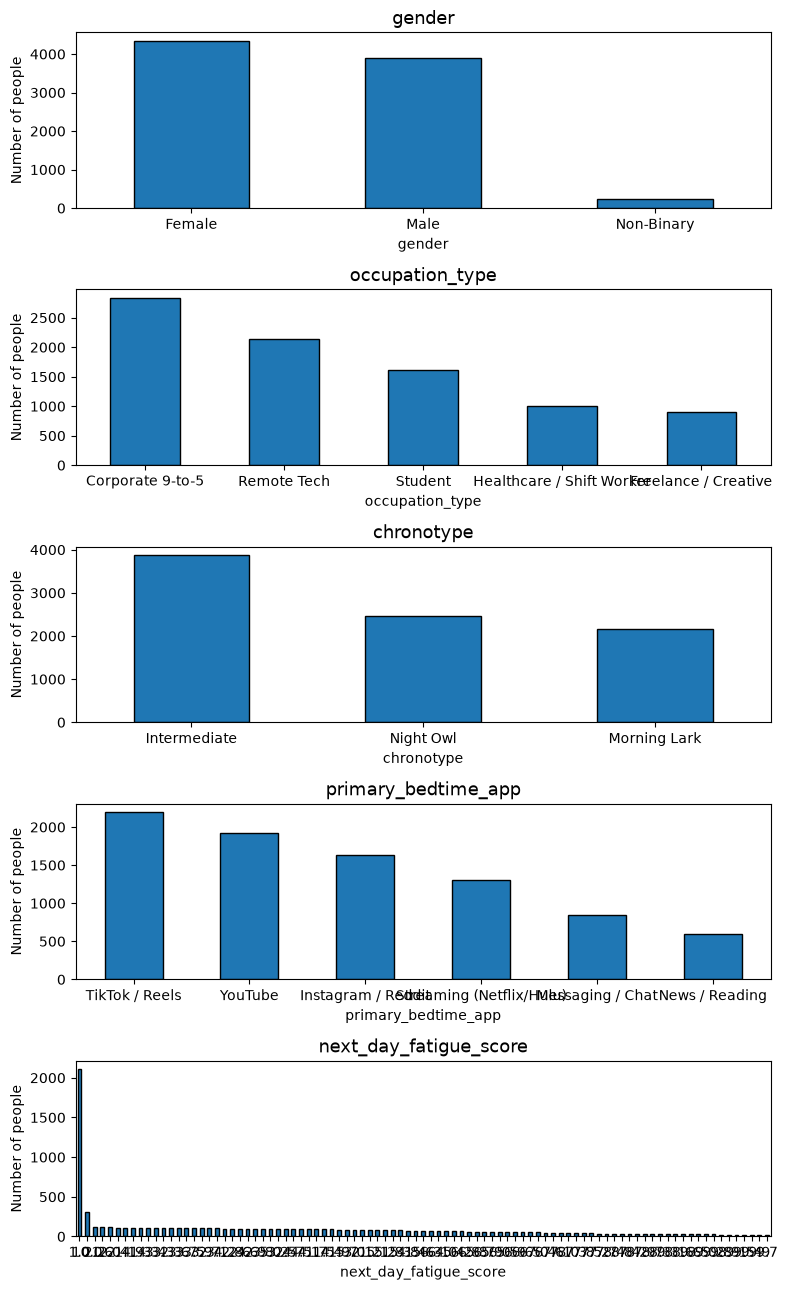

In [127]:
cols_to_plot = categorical_cols + [target_col]

fig, axes = plt.subplots(5, 1, figsize=(8, 13))
axes = axes.flatten()

for i in range(len(cols_to_plot)):
    col = cols_to_plot[i]
    ax = axes[i]
    df[col].value_counts().plot(kind='bar', edgecolor='black', ax=ax)
    ax.set_title(col, fontsize=13)
    ax.set_ylabel('Number of people')
    ax.tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## Question 2

In [128]:
print("Skewness: " + str(round(df[target_col].skew(), 3)))
df[target_col].describe()

Skewness: 0.746


count    8500.000000
mean        3.794671
std         2.685153
min         1.000000
25%         1.100000
50%         3.200000
75%         5.600000
max        10.000000
Name: next_day_fatigue_score, dtype: float64

The classes are imbalanced, because the skewness (asymetry) is greater than 0.5. I will need to stratify and to balance the accuracy.

## Question 3

In [129]:
df = pd.get_dummies(df, columns=categorical_cols, dtype=int)
df

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,...,occupation_type_Student,chronotype_Intermediate,chronotype_Morning Lark,chronotype_Night Owl,primary_bedtime_app_Instagram / Reddit,primary_bedtime_app_Messaging / Chat,primary_bedtime_app_News / Reading,primary_bedtime_app_Streaming (Netflix/Hulu),primary_bedtime_app_TikTok / Reels,primary_bedtime_app_YouTube
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,...,0,1,0,0,1,0,0,0,0,0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,...,1,1,0,0,0,0,0,0,0,1
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,...,0,0,0,1,0,0,0,0,1,0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,...,0,1,0,0,0,0,0,0,0,1
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,...,0,1,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8495,61,18,61,1,60,74,21.0,5.57,26.5,18.1,...,0,0,0,1,0,0,0,1,0,0
8496,64,138,58,1,0,58,84.3,3.99,20.4,19.4,...,1,0,0,1,0,0,0,0,1,0
8497,34,56,56,0,94,33,40.6,7.58,17.4,20.7,...,0,1,0,0,0,0,0,1,0,0
8498,23,165,72,0,0,52,123.3,3.20,14.2,15.8,...,0,0,0,1,0,0,0,0,1,0


## Question 4

In [130]:
X = df.drop(columns=[target_col])
y = df[target_col]

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.1, stratify=pd.qcut(y, 5, labels=False, duplicates='drop'), random_state=0)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2/0.9, stratify=pd.qcut(y_temp, 5, labels=False, duplicates='drop'), random_state=0)

print(len(X_train), len(X_val), len(X_test))

5949 1701 850


## Question 5

In [131]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)

n = len(X_train)
k_values = [3, 5, 15, 50, int(round(np.sqrt(n)))]   # √5949 ≈ 77

results = []
for k in k_values:
    for w in ['uniform', 'distance']:
        knn = KNeighborsRegressor(n_neighbors=k, weights=w).fit(X_train_s, y_train)
        row = {'k': k, 'weights': w}
        for name, Xs, ys in [('train', X_train_s, y_train), ('val', X_val_s, y_val)]:
            p = knn.predict(Xs)
            row[f'MAE {name}'] = mean_absolute_error(ys, p)
            row[f'RMSE {name}'] = np.sqrt(mean_squared_error(ys, p))
            row[f'R2 {name}'] = r2_score(ys, p)
        results.append(row)

df_results = pd.DataFrame(results).round(3)
df_results

,k,weights,MAE train,RMSE train,R2 train,MAE val,RMSE val,R2 val
0,3,uniform,0.634,0.877,0.893,0.921,1.239,0.787
1,3,distance,0.000,0.000,1.000,0.911,1.229,0.791
2,5,uniform,0.711,0.961,0.872,0.897,1.191,0.803
3,5,distance,0.000,0.000,1.000,0.882,1.175,0.809
4,15,uniform,0.838,1.075,0.839,0.933,1.205,0.799
5,15,distance,0.000,0.000,1.000,0.916,1.185,0.805
6,50,uniform,0.920,1.156,0.814,0.961,1.213,0.796
7,50,distance,0.000,0.000,1.000,0.948,1.200,0.801
8,77,uniform,0.951,1.190,0.803,0.987,1.233,0.789
9,77,distance,0.000,0.000,1.000,0.975,1.220,0.794


The best results are for k=5 and weights=distance. i keep these results for the next question.

## Question 6

In [132]:
best_k= 5
best_w ='distance'

# Best model trained on train only
knn = KNeighborsRegressor(n_neighbors=best_k, weights=best_w).fit(X_train_s, y_train)
y_train_pred = knn.predict(X_train_s)
y_val_pred = knn.predict(X_val_s)

# I merge train and validation
X_full = pd.concat([X_train, X_val])
y_full = pd.concat([y_train, y_val])

# New scaler is fitted on train and validation
scaler_full = StandardScaler()
X_full_s = scaler_full.fit_transform(X_full)
X_test_s = scaler_full.transform(X_test)

# Final model and evaluation on test
knn_full = KNeighborsRegressor(n_neighbors=best_k, weights=best_w).fit(X_full_s, y_full)
y_test_pred = knn_full.predict(X_test_s)

# Comparaison of train, validation, test scores
comparison = pd.DataFrame({'Results on train (fitted on train)': {'MAE': mean_absolute_error(y_train, y_train_pred),
        'RMSE': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'R2': r2_score(y_train, y_train_pred)},

    'Results on validation (fitted on train)': {'MAE': mean_absolute_error(y_val, y_val_pred),
        'RMSE': np.sqrt(mean_squared_error(y_val, y_val_pred)),
        'R2': r2_score(y_val, y_val_pred)},

    'Results on test (fitted on train + validation)': {'MAE': mean_absolute_error(y_test, y_test_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'R2': r2_score(y_test, y_test_pred)}
}).T.round(3)

comparison

,MAE,RMSE,R2
Results on train (fitted on train),0.000,0.000,1.000
Results on validation (fitted on train),0.882,1.175,0.809
Results on test (fitted on train + validation),0.863,1.139,0.822


## Question 7

In [133]:
X_train_cv, X_test_cv, y_train_cv, y_test_cv = train_test_split(X, y, test_size=0.1, stratify=pd.qcut(y, 5, labels=False, duplicates='drop'), random_state=0)

# 5-Fold CV on the train set
kf = KFold(n_splits=5, shuffle=True, random_state=0)

n = len(X_train_cv) * 4 // 5  
k_values = [3, 5, 15, 50, int(round(np.sqrt(n)))]

rows = []
for k in k_values:
    for w in ['uniform', 'distance']:
        # Scaler inside the Pipeline, so it is refitted on each fold
        pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=k, weights=w))])
        cv = cross_validate(pipe, X_train_cv, y_train_cv, cv=kf, scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'])
        rows.append({'k': k,
            'weights': w,
            'MAE': -cv['test_neg_mean_absolute_error'].mean(),
            'RMSE': -cv['test_neg_root_mean_squared_error'].mean(),
            'R2': cv['test_r2'].mean()})

cv_results = pd.DataFrame(rows).round(3)
cv_results

,k,weights,MAE,RMSE,R2
0,3,uniform,0.905,1.227,0.791
1,3,distance,0.897,1.217,0.794
2,5,uniform,0.876,1.167,0.811
3,5,distance,0.866,1.154,0.815
4,15,uniform,0.892,1.146,0.818
5,15,distance,0.877,1.129,0.823
6,50,uniform,0.936,1.174,0.808
7,50,distance,0.922,1.160,0.813
8,78,uniform,0.964,1.202,0.799
9,78,distance,0.951,1.188,0.804


The best parameters are k=15 and weights=distance

In [134]:
# Best combination (lowest RMSE)
best_k = 15
best_w = 'distance'

pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=best_k, weights=best_w))])
cv = cross_validate(pipe, X_train_cv, y_train_cv, cv=kf,
                    scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'])

# 95 % CI: mean ± t * s / √5
t = 2.776
mae = -cv['test_neg_mean_absolute_error']
rmse = -cv['test_neg_root_mean_squared_error']
r2 = cv['test_r2']

ci_table = pd.DataFrame({
    'Mean': [mae.mean(), rmse.mean(), r2.mean()],
    'CI low': [mae.mean() - t * mae.std(ddof=1) / np.sqrt(5),
               rmse.mean() - t * rmse.std(ddof=1) / np.sqrt(5),
               r2.mean() - t * r2.std(ddof=1) / np.sqrt(5)],
    'CI high': [mae.mean() + t * mae.std(ddof=1) / np.sqrt(5),
                rmse.mean() + t * rmse.std(ddof=1) / np.sqrt(5),
                r2.mean() + t * r2.std(ddof=1) / np.sqrt(5)]
}, index=['MAE', 'RMSE', 'R2']).round(3)

ci_table

,Mean,CI low,CI high
MAE,0.877,0.861,0.893
RMSE,1.129,1.104,1.154
R2,0.823,0.813,0.833


## Question 8

In [135]:
pipe = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor())])

param_grid = {'knn__n_neighbors': k_values,'knn__weights': ['uniform', 'distance']}

# In the Inner loop: GridSearch with 5-fold CV, best model chosen depending on RMSE
grid = GridSearchCV(pipe, param_grid, cv=KFold(n_splits=5, shuffle=True, random_state=0), scoring='neg_root_mean_squared_error')

# Outer loop: 3-fold CV
nested = cross_validate(grid, X_train_cv, y_train_cv, cv=KFold(n_splits=3, shuffle=True, random_state=0),
                        scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'],
                        return_estimator=True)

nested_results = pd.DataFrame({
    'Best k': [est.best_params_['knn__n_neighbors'] for est in nested['estimator']],
    'Best weights': [est.best_params_['knn__weights'] for est in nested['estimator']],
    'MAE': -nested['test_neg_mean_absolute_error'],
    'RMSE': -nested['test_neg_root_mean_squared_error'],
    'R2': nested['test_r2']
}, index=['Fold 1', 'Fold 2', 'Fold 3']).round(3)

nested_results

,Best k,Best weights,MAE,RMSE,R2
Fold 1,15,distance,0.903,1.165,0.810
Fold 2,15,distance,0.891,1.151,0.822
Fold 3,15,distance,0.875,1.128,0.819


In the end, we have proven that the best hyper parameters are k=15 and weights=distance